### Homework 02
Igor Di Tota

Bertrand paradox e la dipendenza della probabilita' dalla scelta di definizione di corda

Mia definizione di corda: scelti due punti casuali all'interno del disco (cerchio + bordo) e traccio la corda che li unisce.


In [7]:
import numpy as np
import matplotlib.pyplot as plt
import os
os.makedirs("images", exist_ok=True)

rng = np.random.default_rng(23)
R = 1.0
theta_vertex = np.deg2rad(110)  # Angular position of the first vertex of the triangle (slightly rotated)
side = R * np.sqrt(3)           # Side of the inscribed equilateral triangle

In the next cell I define the functions that I will use to:
1. generate random points inside the circle
2. obtain the endpoints of the chord and its length
3. plot the circle and the triangle


In [8]:
'''
random_points_in_disk generates n random points uniformly distributed inside a disk of radius R.
The function uses the fact that to have points uniform in area,
the radius r should be scaled by the square root of a uniform random variable U.
This is because the area of a ring between r and r+dr grows like r,
so using r = R*U would accumulate too many points near the center of the disk.
The function returns an array of shape (n, 2) containing the x and y coordinates of the points.
'''
def random_points_in_disk(n):
    r = R * np.sqrt(rng.uniform(size=n))
    phi = rng.uniform(0, 2 * np.pi, size=n)
    return np.column_stack((r * np.cos(phi), r * np.sin(phi)))

'''
chord_from_points takes two points p1 and p2 inside the disk and returns the endpoints of the chord and its length.
'''
def chord_from_points(p1, p2):
    x1, y1 = p1
    x2, y2 = p2

    # Line through P1 and P2:  x(t) = x1 + t*dx,  y(t) = y1 + t*dy
    dx = x2 - x1
    dy = y2 - y1

    # Intersection with the circle x^2 + y^2 = R^2  ->
    # -> second degree equation in t:  a t^2 + b t + c = 0
    a = dx**2 + dy**2
    b = 2 * (x1 * dx + y1 * dy)
    c = x1**2 + y1**2 - R**2
    delta = b**2 - 4 * a * c

    t_minus = (-b - np.sqrt(delta)) / (2 * a)
    t_plus  = (-b + np.sqrt(delta)) / (2 * a)
    
    # Endpoints of the chord
    A = (x1 + t_minus * dx, y1 + t_minus * dy)
    B = (x1 + t_plus * dx,  y1 + t_plus * dy)

    # Length
    L = np.sqrt((B[0] - A[0])**2 + (B[1] - A[1])**2)

    return A, B, L

'''
draw_base draws the figure of the circle and the triangle on the given axes.
'''
def draw_base(ax, col):
    # Circle and inscribed equilateral triangle
    tt = np.linspace(0, 2 * np.pi, 1000)
    ax.plot(R * np.cos(tt), R * np.sin(tt), c="black", lw=1.5)

    # Define the vertex angles of the triangle, since the triangle is equilateral, the others are found with steps of 120 degrees
    v = theta_vertex + np.array([0, 2, 4, 0]) * np.pi / 3
    ax.plot(R * np.cos(v), R * np.sin(v), c=col, lw=1.5)
    ax.set_aspect("equal")
    ax.axis("off")  #We don't need axes


In this cell, I illustrate the process that leads from the two random points inside the circle to the definition of the chord, and finally to the comparison of the length of the chord with the side of the inscribed equilateral triangle.

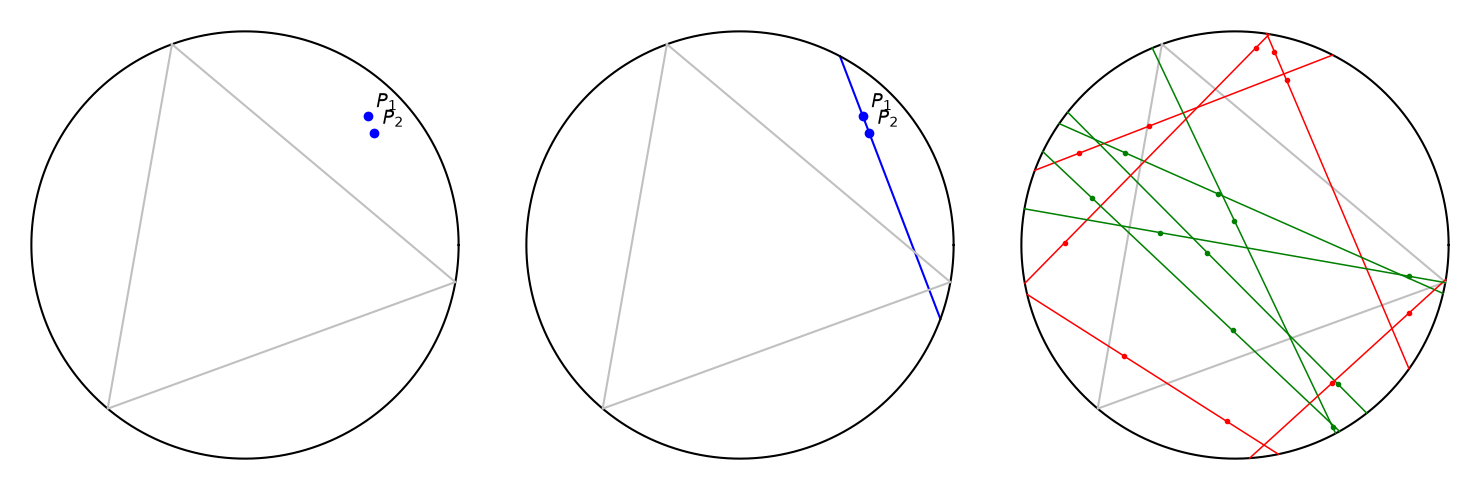

In [9]:

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

#  Ax_0: two random points inside the disk
p1, p2 = random_points_in_disk(2)
draw_base(axes[0], "silver")
for ax in axes[:2]:
    ax.plot(*p1, "o", c="blue")
    ax.plot(*p2, "o", c="blue")
    ax.annotate(r"$P_1$", p1, xytext=(6, 6), textcoords="offset points", fontsize=14)
    ax.annotate(r"$P_2$", p2, xytext=(6, 6), textcoords="offset points", fontsize=14)

# Ax_1: two points -> chord
A, B, L = chord_from_points(p1, p2)
draw_base(axes[1], "silver")
axes[1].plot([A[0], B[0]], [A[1], B[1]], c="blue", lw=1.5, zorder=0)

# Ax_2: example with 10 random chords
draw_base(axes[2], "silver")
for i in range(10):
    q1, q2 = random_points_in_disk(2)
    A, B, L = chord_from_points(q1, q2)
    if L > side:
        col = "green"
    else:
        col = "red"
    axes[2].plot([A[0], B[0]], [A[1], B[1]], c=col, lw=1.1)
    axes[2].plot([q1[0], q2[0]], [q1[1], q2[1]], "o", c=col, ms=3)



plt.tight_layout()
plt.savefig("images/chord_definition.pdf", dpi=300)
plt.show()


In [13]:
N = 1000   # Total number of extractions

# Two sets of N random points inside the disk
p1 = random_points_in_disk(N)
p2 = random_points_in_disk(N)

A, B, L = chord_from_points(p1.T, p2.T)

# Number of chords longer than the side of the triangle
n_long = np.sum(L > side)

# Probability and its standard deviation
# n_long follows a binomial distribution: Var(n_long) = N p (1-p)
# sigma_P = sqrt(Var(n_long) / N^2) = sqrt(p (1-p) / N)
P = n_long / N
sigma_P = np.sqrt(P * (1 - P) / N)

print(f"Number of extractions:          N = {N}")
print(f"Chords longer than the side:    {n_long}")
print(f"Probability:        P = {P:.4f} +/- {sigma_P:.4f}")


Number of extractions:          N = 1000
Chords longer than the side:    751
Probability:        P = 0.7510 +/- 0.0137


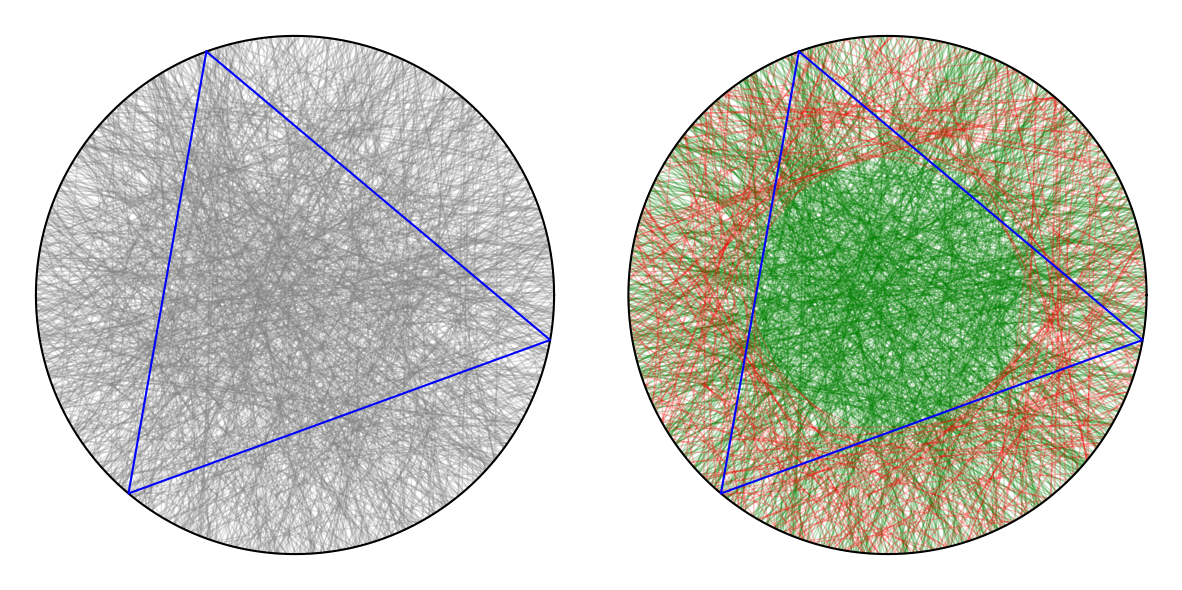

In [14]:
# True if the chord is longer than the side of the triangle
long = L > side

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Ax_0: all chords in grey
draw_base(axes[0], "blue")
axes[0].plot([A[0], B[0]], [A[1], B[1]], c="grey", lw=1, alpha=0.25, zorder=0)

# Ax_1: same chords, green if longer than the side, red otherwise
draw_base(axes[1], "blue")
axes[1].plot([A[0][long],  B[0][long]],  [A[1][long],  B[1][long]],  c="green", lw=1, alpha=0.25, zorder=0)
axes[1].plot([A[0][~long], B[0][~long]], [A[1][~long], B[1][~long]], c="red",   lw=1, alpha=0.25, zorder=0)

plt.tight_layout()
plt.savefig("images/chords_distribution.pdf")
plt.show()

### Dependence of the estimate on the number of extractions

In the next cell is studied how the estimate of the probability improves with the number of extractions.
The procedure is repeated for $N = 10^2, \dots, 10^7$ chords.

For each $N$ the uncertainty of the probability is computed from the binomial distribution.
$\sigma_P = \sqrt{P(1-P)/N}$ is plotted as a function of $N$ in log-log scale and fitted with a line:
$$\log_{10}\sigma_P = \alpha \, \log_{10}N + c \qquad \Longleftrightarrow \qquad \sigma_P \propto N^{\alpha}.$$

The expected value is $\alpha = -1/2$.

N = 10^k:
k = 2:  P = 0.70000 +/- 0.04583
k = 3:  P = 0.73800 +/- 0.01391
k = 4:  P = 0.75450 +/- 0.00430
k = 5:  P = 0.74784 +/- 0.00137
k = 6:  P = 0.74734 +/- 0.00043
k = 7:  P = 0.74656 +/- 0.00014

Slope of sigma(N): -0.5036 +/- 0.0019


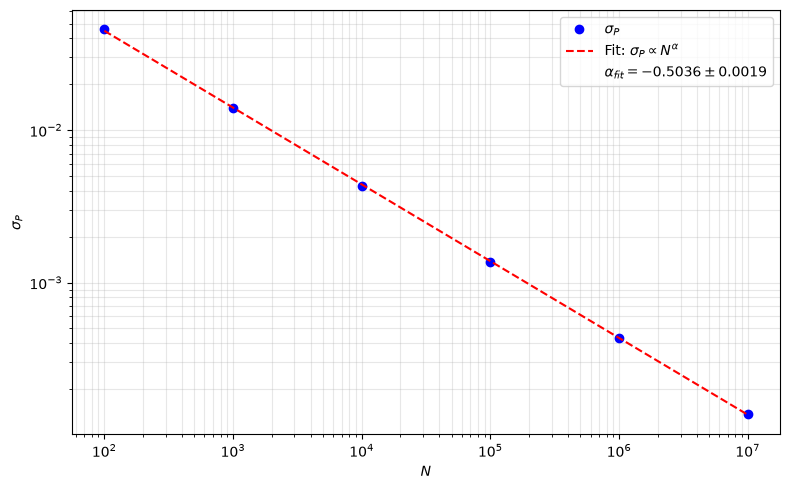

In [38]:
from scipy.optimize import curve_fit

N_values = np.array([10**k for k in range(2, 8)])
P_values = np.zeros(len(N_values))
sigma_values = np.zeros(len(N_values))

print("N = 10^k:")
for i, n in enumerate(N_values):
    _, _, L_n = chord_from_points(random_points_in_disk(n).T, random_points_in_disk(n).T)
    P_values[i] = np.sum(L_n > side) / n
    sigma_values[i] = np.sqrt(P_values[i] * (1 - P_values[i]) / n)
    print(f"k = {i+2}:  P = {P_values[i]:.5f} +/- {sigma_values[i]:.5f}")


def line(x, slope, const):
    return slope * x + const

par, cov = curve_fit(line, np.log10(N_values), np.log10(sigma_values))
slope, const = par
err_slope = np.sqrt(cov[0, 0])

print(f"\nSlope of sigma(N): {slope:.4f} +/- {err_slope:.4f}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(N_values, sigma_values, "o", c="blue", label=r"$\sigma_P$")

NN = np.logspace(2, 7, 200)
ax.plot(NN, 10**line(np.log10(NN), *par), "--", c="red", label=r"Fit: $\sigma_P \propto N^{{\alpha}}$")
ax.plot([], [], " ", label=rf"$\alpha_{{fit}} = {slope:.4f} \pm {err_slope:.4f}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("$N$")
ax.set_ylabel(r"$\sigma_P$")
ax.legend()
ax.grid(alpha=0.3, which="both")

plt.tight_layout()
plt.savefig("images/convergence.pdf")
plt.show()
